# Sentence embeddings vs TF-IDF n-grams

`all-MiniLM-L6-v2` (pinned commit, CPU) turns each review into 384 numbers; logistic regression on those is compared with the day 5 TF-IDF n-gram model on the same validation set. Run by `make embeddings`, which writes `reports/embeddings.json`.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("REVIEWS_DATA_DIR", "../data")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from reviews.compare import load
from reviews.evaluate import paired_difference
from reviews.model_store import load_model

saved = json.loads(Path("../reports/embeddings.json").read_text())
{
    k: saved[k]
    for k in [
        "encode_seconds",
        "accuracy_by_C",
        "embeddings",
        "tfidf_ngrams_accuracy",
        "embeddings_minus_tfidf_95",
    ]
}

{'encode_seconds': {'validation': 615.3, 'train': 7598.5},
 'accuracy_by_C': {'0.1': 0.866, '1.0': 0.8684, '10.0': 0.8696},
 'embeddings': {'accuracy': 0.8696,
  'f1_negative': 0.8699511319437518,
  'accuracy_95': [0.865, 0.8741],
  'f1_negative_95': [0.865, 0.8747],
  'auc': 0.9403120150000002},
 'tfidf_ngrams_accuracy': 0.9348,
 'embeddings_minus_tfidf_95': [-0.0702, -0.0605]}

- **Embeddings: 87.0%** (86.5 to 87.4), against **93.5%** for TF-IDF n-grams. The paired difference is 6.0 to 7.0 points in TF-IDF's favour.
- C barely matters: 86.6% at 0.1, 87.0% at 10. The best is at the edge of the grid, but 0.4 points over two decades of C won't close a 6.5-point gap, so I didn't widen it.
- **Cost**: encoding the 200k training reviews took 2 h 7 min on a laptop CPU (about 26 reviews a second), even with length-sorted batches. The TF-IDF model fits in 2.5 minutes.

## Where each one fails

In [2]:
train_x, train_y = load("train")
val_x, val_y = load("validation")
emb = Path(os.environ["REVIEWS_DATA_DIR"]) / "embeddings"
e_train = np.load(next(emb.glob("train-*.npy")), allow_pickle=False)
e_val = np.load(next(emb.glob("validation-*.npy")), allow_pickle=False)
clf = LogisticRegression(C=saved["best_C"], max_iter=3000).fit(e_train, train_y)
p_emb = clf.predict_proba(e_val)[:, 1]
grams = json.loads(Path("../reports/ngrams.json").read_text())
tfidf = load_model(Path("../models/ngrams-best"), grams["winner_sha256"]).model
p_tfidf = tfidf.predict_proba(val_x)[:, 1]
y = val_y.to_numpy()
right_emb, right_tfidf = (p_emb >= 0.5) == y, (p_tfidf >= 0.5) == y
assert round(right_emb.mean(), 4) == saved["embeddings"]["accuracy"]
pd.crosstab(right_emb, right_tfidf, rownames=["embeddings right"], colnames=["tf-idf right"])

tf-idf right,False,True
embeddings right,,
False,686,1922
True,618,16774


TF-IDF makes 1,304 mistakes and embeddings fix 618 of them, so the two aren't wrong about the same reviews as often as the accuracy gap suggests.

In [3]:
length = np.array([len(t) for t in val_x])
bins = pd.cut(
    length, [0, 200, 400, 700, np.inf], right=False, labels=["<200", "200-400", "400-700", "700+"]
)
by_len = pd.DataFrame({"embeddings": right_emb, "tf-idf n-grams": right_tfidf})
by_len = by_len.groupby(bins, observed=True).mean() * 100
by_len.insert(0, "reviews", pd.Series(bins).value_counts().reindex(by_len.index).values)
by_len.round(1)

,reviews,embeddings,tf-idf n-grams
<200,3830,89.5,94.3
200-400,6542,88.0,93.6
400-700,6293,86.6,93.5
700+,3335,82.5,92.3


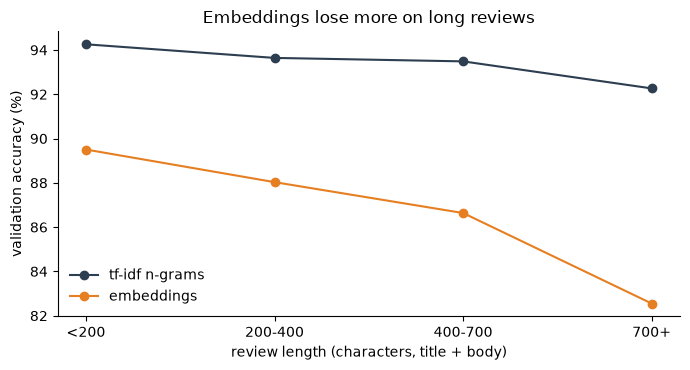

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for col, colour in [("tf-idf n-grams", "#2c3e50"), ("embeddings", "#e67e22")]:
    ax.plot(by_len.index.astype(str), by_len[col], "o-", label=col, color=colour)
ax.set_xlabel("review length (characters, title + body)")
ax.set_ylabel("validation accuracy (%)")
ax.set_title("Embeddings lose more on long reviews")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/embeddings_by_length.png", dpi=150)

The gap grows with length: 4.8 points under 200 characters, about 10 points over 700. The model reads at most 256 tokens and averages everything it reads into one vector, so a long review with mixed parts gets blurred. TF-IDF keeps every phrase as its own feature.

## The day 7 mistakes

In [5]:
labels = pd.read_csv("../reports/error_labels.csv")
labels["embeddings_right"] = (p_emb[labels["row"]] >= 0.5).astype(int) == labels["true"]
labels.groupby("cause")["embeddings_right"].agg(["sum", "count"])

,sum,count
cause,,
elsewhere,4,15
label,1,2
language,1,1
mixed,8,16
no opinion,1,3
sarcasm,3,3
wording,4,10


Embeddings get 22 of the 50 labelled TF-IDF mistakes right, including all 3 sarcastic ones and half the mixed reviews. Three is too few to say they handle sarcasm, though.

## Do they help together?

In [6]:
rows = []
for w in (0.2, 0.3, 0.5):
    p = w * p_emb + (1 - w) * p_tfidf
    pred = (p >= 0.5).astype(int)
    lo, hi = paired_difference(val_y, pred, (p_tfidf >= 0.5).astype(int))
    rows.append(
        {
            "embedding weight": w,
            "accuracy": (pred == y).mean(),
            "vs tf-idf, 95%": f"{lo:+.2%} to {hi:+.2%}",
        }
    )
pd.DataFrame(rows)

,embedding weight,accuracy,"vs tf-idf, 95%"
0,0.2,0.9378,+0.15% to +0.46%
1,0.3,0.9382,+0.16% to +0.53%
2,0.5,0.9321,-0.57% to +0.01%


An even average is no better than TF-IDF alone (if anything slightly worse). Weight 0.3 gains 0.2 to 0.5 points, but that weight was picked on this same validation set, so the gain is optimistic.

## Decision

TF-IDF n-grams stay the model (decision 15). Embeddings are 6.5 points less accurate on their own. Mixing them in buys a fraction of a point, and it needs a 90 MB encoder and about 40 ms of CPU per review, against microseconds for TF-IDF. For the CLI that isn't worth it. They might be worth it with a model fine-tuned on reviews, or a longer context, but that's outside this project.